# Lab 14: How to search your documents with LlamaIndex

**Notebook 1 of 2: meet LlamaIndex on a folder of notes (challenge solved)**

## Goal

We have just moved into a new flat, and everything we were told is in a folder of short notes. The question for this
notebook is an everyday one: *When can I call someone about the internet?* The answer is in two notes, and only one of
them mentions the internet.

LlamaIndex is a framework for connecting a model to your own documents. We meet its objects one at a time, and print
each one when it first appears: the settings, a document, a folder reader, an index, a retriever and a query engine.
Then we give the search to an agent in two ways and read what each one hands back. A **query-engine tool** returns a
sentence that a second model call wrote about the notes. A **retriever tool** returns the notes themselves. Notebook 2
takes the same choice to the Chinook music shop's support desk.

## What you will learn

- How to check which models LlamaIndex will call, and set them from `models.env` with `Settings`.
- How a `Document` holds a text, and how `SimpleDirectoryReader` turns a folder of files into documents.
- How to index documents with `VectorStoreIndex`, and read what a retriever returns and how it scores it.
- How a query engine writes an answer from what it retrieved, where its sources are, and which prompt it fills in.
- How to give a search to a `FunctionAgent` as a query-engine tool or as a retriever tool, and read what each tool
  handed back.

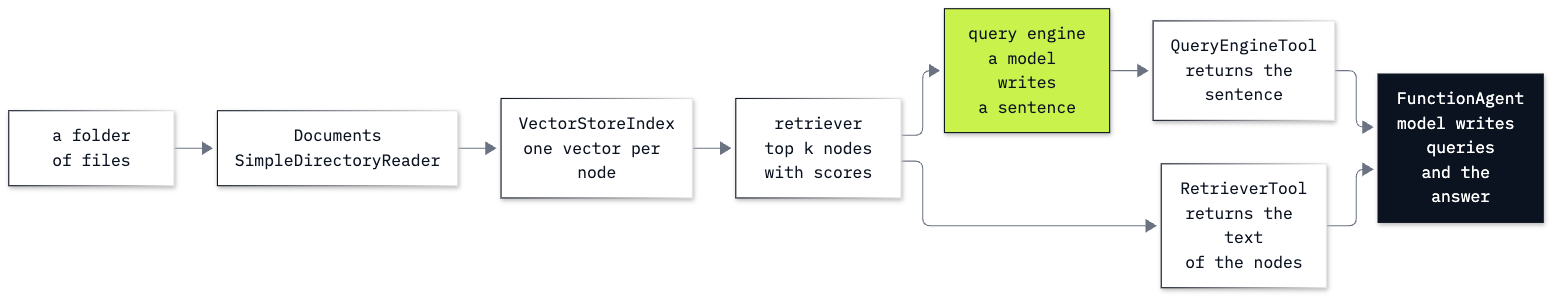

In [1]:
from IPython.display import Image

Image("../resources/lab14_documents_to_answer.png", width=760)

Read the picture from the left. Up to the retriever, it is search: the embedding model turns text into vectors and
nothing writes an answer. On the right are the two ways to hand that search to an agent. Watch the lime box, the query
engine: there, a model call sits between the notes and the agent.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model names from `models.env`, and
takes the key from `.env` without printing it.

In [2]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


---

## Part A: Check which models LlamaIndex will call, then choose them

LlamaIndex calls two kinds of model. An **embedding model** turns each text, and each question, into a vector (a list
of numbers), so that texts with similar meaning can be found by comparing vectors. An **LLM** (large language model)
writes text: answers, and the agent's requests for tools. Both come from `Settings`, a set of defaults that every
LlamaIndex object reads when we do not pass a model ourselves.

Before we set anything, here is what `Settings` holds:

In [3]:
from llama_index.core import Settings

print("LLM:      ", Settings.llm.model)
print("embedding:", Settings.embed_model.model_name)
print("models.env names:", MODEL, "and", settings["EMBEDDING_MODEL"])

LLM:       gpt-3.5-turbo
embedding: text-embedding-ada-002
models.env names: gpt-6-luna and text-embedding-3-small


Left alone, LlamaIndex uses its own default models, printed above: an older chat model to write and an older embedding
model to embed. Both are OpenAI models, and neither is a model that `models.env` names.

**Important:** nothing failed. Code that forgets this step runs without an error, on models (and at prices) that
nobody chose. So we build both models from `models.env` and make them the defaults:

- `OpenAI` from `llama_index.llms.openai` is LlamaIndex's wrapper for OpenAI's chat models. It shares its name with
  the client in the `openai` library, but it is a different class. We pass the model name and the reasoning effort.
- `OpenAIEmbedding` is LlamaIndex's wrapper for OpenAI's embedding models.

In [4]:
from llama_index.llms.openai import OpenAI
from llama_index.embeddings.openai import OpenAIEmbedding

Settings.llm = OpenAI(model=MODEL, reasoning_effort=EFFORT)
Settings.embed_model = OpenAIEmbedding(model=settings["EMBEDDING_MODEL"])

print("LLM:      ", Settings.llm.model)
print("embedding:", Settings.embed_model.model_name)

LLM:       gpt-6-luna
embedding: text-embedding-3-small


Now both are the models `models.env` names, and every object we build from here on uses them.

First, the question with no notes at all. `Settings.llm.complete` sends one message to the model and returns its
reply.

In [5]:
QUESTION = "When can I call someone about the internet?"

print(Settings.llm.complete(QUESTION))

You can call your internet provider’s customer support whenever you need help. If you mean the best time to reach them, check their website or your bill for their phone hours—support hours vary by provider.


In our run the reply was general advice: contact your internet provider's customer service, and say which provider and where. Nothing about this flat, its notes or Sam Haddad was in the request, so the model could not write it. To answer, the model needs our notes in front of it, and the rest of this notebook builds that.

**Checkpoint A.** Before we set them, `Settings` names models that are not the ones in `models.env`; after, it names
ours. With no notes, the reply gives general advice and nothing about this flat.

---

## Part B: Represent a note as a Document, then read the whole folder

Everything LlamaIndex searches starts as a `Document`: a text, plus facts about where it came from. Here is the
smallest one, built by hand from one sentence:

In [6]:
from llama_index.core import Document

note = Document(text="The washing machines are in the basement.")
print(note)

Doc ID: aef2dd77-1c41-4282-b8a7-5ebe504c086b
Text: The washing machines are in the basement.


Printed, a `Document` shows two fields:

- **`Doc ID`**: an id LlamaIndex made up, because we did not give one. Run the cell again and it changes.
- **`Text`**: our sentence, unchanged.

That is all a `Document` needs. Our notes are files, so next we look at the folder. It is in this lab's
`resources/new_flat/`, seven short markdown files:

In [7]:
FLAT = Path("../resources/new_flat")

for path in sorted(FLAT.glob("*.md")):
    print(path.name)

haddad.md
landlord.md
laundry.md
move_in.md
neighbours.md
plumber.md
shops.md


The note we are given on moving day is `move_in.md`:

In [8]:
print((FLAT / "move_in.md").read_text())

# Moving in

Keys: two front-door keys and one post-box key, in the envelope on the kitchen counter.

Internet: not connected yet. Ask the building manager, Sam Haddad.

Electricity meter: in the cupboard by the front door. Take a photo of the reading on the first day.



The internet line names a person, **Sam Haddad**, and says nothing about when to call him. His details are in
another note:

In [9]:
print((FLAT / "haddad.md").read_text())

# Sam Haddad

Lives in flat 1, on the ground floor, with his brother and a very old dog called Biscuit.

Keeps the key to the roof and the bike room.

Phone: 555-0114. Answers from 18:00 to 20:00, Monday to Friday.



So the answer needs two notes, read in order:

1. `move_in.md`: for the internet, ask the building manager, Sam Haddad.
2. `haddad.md`: Sam Haddad answers from 18:00 to 20:00, Monday to Friday.

Notice that `haddad.md` never says *internet* or *building manager*. The only link between the two notes is the name.

### Read the folder with `SimpleDirectoryReader`

We could build seven `Document`s by hand. `SimpleDirectoryReader` does it for a whole folder: one `Document` per
file, with **metadata**, facts about the file stored beside its text. Here is what it stores when we take its
defaults (the names of the metadata fields only):

In [10]:
from llama_index.core import SimpleDirectoryReader

default_documents = SimpleDirectoryReader(FLAT).load_data()
print(len(default_documents), "documents")
print(list(default_documents[0].metadata))

7 documents
['file_path', 'file_name', 'file_type', 'file_size', 'creation_date', 'last_modified_date']


Seven documents, one per file, each with six metadata fields. One of them is a problem: **`file_path` is the full
path of the file on your computer**, with your user name in it, and the reader puts that path at the top of the text
that every model call reads. We do not want that sent with every question. You can see the text a model receives with
`default_documents[0].get_content(metadata_mode="llm")`; we do not print it here, because its first line is the
path on our computer.

`file_metadata=` lets us choose the metadata ourselves. It takes a function that receives a file's path and returns
the metadata as a dictionary. `keep_name` keeps the file's name and nothing else (`Path(path).name` is the last part
of the path, for example `move_in.md`). The reader leaves the name out of what the models read and keeps it for our
code.

In [11]:
def keep_name(path):
    return {"file_name": Path(path).name}


documents = SimpleDirectoryReader(FLAT, file_metadata=keep_name).load_data()
for document in documents:
    print(f"{document.metadata['file_name']:15} {document.text.splitlines()[0]}")

haddad.md       # Sam Haddad
landlord.md     # Landlord
laundry.md      # Laundry
move_in.md      # Moving in
neighbours.md   # Neighbours
plumber.md      # Plumber
shops.md        # Shops nearby


Seven documents, each with only its file name as metadata, printed beside the first line of its text. The name is
kept for our code and left out of what the models read: `documents[0].get_content(metadata_mode="llm")` now starts
with `# Sam Haddad`, the note's own first line.

**Checkpoint B.** A hand-built `Document` prints a made-up id and its text. The folder holds seven notes, and the answer
needs two of them: `move_in.md` (ask Sam Haddad) and `haddad.md` (his hours). `SimpleDirectoryReader` with `keep_name`
gives seven documents whose only metadata is `file_name`.

---

## Part C: Index the notes and read what a retriever returns

To search the notes, every one of them needs a vector. `VectorStoreIndex.from_documents` does three jobs in one line:

1. It splits each document into **nodes**, the pieces LlamaIndex searches. A long manual would become many nodes; our
   notes are a few lines each, so each note stays one node.
2. It embeds each node with `Settings.embed_model`.
3. It keeps the vectors in a vector store, here one that lives in memory.

In [12]:
from llama_index.core import VectorStoreIndex

index = VectorStoreIndex.from_documents(documents)
print(type(index).__name__, "with", len(index.docstore.docs), "nodes")

VectorStoreIndex with 7 nodes


Seven nodes, one per note.

A **retriever** takes a question, embeds it with the same model, and returns the nodes whose vectors are closest.
`index.as_retriever()` makes one with LlamaIndex's default number of results, `DEFAULT_SIMILARITY_TOP_K`. Before you
run it: which two notes will come back for our question?

In [13]:
from llama_index.core.constants import DEFAULT_SIMILARITY_TOP_K

retriever = index.as_retriever()
results = retriever.retrieve(QUESTION)

print("default top k:", DEFAULT_SIMILARITY_TOP_K)
for result in results:
    print(f"{result.score:.3f}  {result.node.metadata['file_name']}")

default top k: 2
0.303  move_in.md
0.302  landlord.md


The default top k is **2**, so we get two results. Each is a `NodeWithScore`: the `node` (its text and metadata), and
a `score`, the cosine similarity between the question's vector and the node's. Higher means closer.

In our run, `move_in.md` came first (0.303): it is the one note about the internet. `landlord.md` came second (0.302): it is about calling someone, Mrs Clara Chen, at certain hours, which is close to our question in meaning, though not about the internet. `haddad.md`, which holds the hours we need, did not make the top 2. Its text is about a person, his flat and his phone, and shares little meaning with *internet*.

**Important:** the retriever returns the nearest notes, not the notes that answer. A note that shares no meaning with
the question, like `haddad.md` here, can hold half the answer.

**Checkpoint C.** Seven nodes in the index. Default top k 2: `move_in.md` (0.303) and `landlord.md` (0.302), and not `haddad.md`.

---

## Part D: Ask a query engine, and read its sources and its prompt

A retriever returns notes, not an answer. A **query engine** goes one step further: it retrieves (top 2 by default),
puts the notes' text into a prompt, makes one model call, and returns the reply as a `Response`.

In [14]:
query_engine = index.as_query_engine()
response = query_engine.query(QUESTION)

print(response)

You can ask the building manager, Sam Haddad, about the internet. No specific time is given.


In our run: *Ask the building manager, Sam Haddad. No calling hours are specified.* The first half is right. The second half is a claim about the notes, and it is wrong: `haddad.md` gives the hours.

A `Response` keeps the notes it was written from in `response.source_nodes`, the same kind of `NodeWithScore` the
retriever returned:

In [15]:
for source in response.source_nodes:
    print(f"{source.score:.3f}  {source.node.metadata['file_name']}")

0.303  move_in.md
0.302  landlord.md


The same two notes the retriever returned, with the same scores: `move_in.md` and `landlord.md`.

**Always read the sources beside the answer.** The answer says that no time is given. The sources show why:
`haddad.md`, the note that gives the time, was never in front of the model. The answer is about two notes, and it
reads as if it were about all seven.

What did the model receive? `query_engine.get_prompts()` returns the prompt templates the engine fills in, by name.
The one used for a question is `text_qa_template`; `get_template(llm=...)` prints the version for our model, a chat
model, as its messages.

In [16]:
prompts = query_engine.get_prompts()
print(list(prompts))
print()
print(prompts["response_synthesizer:text_qa_template"].get_template(llm=Settings.llm))

['response_synthesizer:text_qa_template', 'response_synthesizer:refine_template', 'response_synthesizer:chat_content_qa_template', 'response_synthesizer:chat_content_refine_template']

system: You are an expert Q&A system that is trusted around the world.
Always answer the query using the provided context information, and not prior knowledge.
Some rules to follow:
1. Never directly reference the given context in your answer.
2. Avoid statements like 'Based on the context, ...' or 'The context information ...' or anything along those lines.
user: Context information is below.
---------------------
{context_str}
---------------------
Given the context information and not prior knowledge, answer the query.
Query: {query_str}
Answer: 
assistant: 


Four templates. Ours is `text_qa_template`. `refine_template` takes over when the retrieved text is too long for one
call; the two `chat_content_` templates are for context that arrives as chat messages, which our query does not use.
Read ours from the top:

- A **system** message, written by LlamaIndex: answer from the context, not from prior knowledge, and never mention
  the context. Rules 1 and 2 are why the answer names no note.
- A **user** message: the retrieved notes go where `{context_str}` is, between the dashed lines, and our question goes
  where `{query_str}` is.

The engine only puts the notes and the question into this template. The problem comes before that: the retriever
passed two notes, and `haddad.md`, the second note the answer needs, was not one of them.

**Checkpoint D.** One answer from the query engine, written from `move_in.md` and `landlord.md`, that does not give
Sam Haddad's hours; four prompt templates, the question template with a system and a user message.

---

## Part E: Wrap the search as two tools and call each by hand

An agent searches by calling a tool. LlamaIndex turns each of our two objects into a tool:

- `QueryEngineTool` wraps the query engine. Calling it runs the engine: retrieve, one model call, a sentence back.
- `RetrieverTool` wraps the retriever. Calling it runs the search and returns the text of each node found. No model
  writes anything.

We give both the same name and the same description, so that the only difference is what comes back. The description
is what the agent's model reads to decide when to call the tool.

In [17]:
import json

from llama_index.core.tools import QueryEngineTool, RetrieverTool

DESCRIPTION = "Search my notes about the new flat."

qe_tool = QueryEngineTool.from_defaults(query_engine=query_engine, name="search_notes", description=DESCRIPTION)
rt_tool = RetrieverTool.from_defaults(retriever=retriever, name="search_notes", description=DESCRIPTION)

print(json.dumps(qe_tool.metadata.to_openai_tool(), indent=2))

{
  "type": "function",
  "function": {
    "name": "search_notes",
    "description": "Search my notes about the new flat.",
    "parameters": {
      "properties": {
        "input": {
          "title": "Input",
          "type": "string"
        }
      },
      "required": [
        "input"
      ],
      "type": "object"
    }
  }
}


This is the tool schema the agent's model will see, written by LlamaIndex from the name and the description: one
required string argument, called `input`. The retriever tool's schema is the same.

Now both tools called by hand, on the same input, our question. `tool.call(input=...)` runs a tool and returns a
`ToolOutput`; its `.content` is the text an agent would read.

In [18]:
print("QUERY-ENGINE TOOL")
print(qe_tool.call(input=QUESTION).content)
print()
print("RETRIEVER TOOL")
print(rt_tool.call(input=QUESTION).content)

QUERY-ENGINE TOOL


You can ask the building manager, Sam Haddad, about the internet. No specific calling time is provided.

RETRIEVER TOOL


# Moving in

Keys: two front-door keys and one post-box key, in the envelope on the kitchen counter.

Internet: not connected yet. Ask the building manager, Sam Haddad.

Electricity meter: in the cupboard by the front door. Take a photo of the reading on the first day.

# Landlord

Rent goes to Mrs Clara Chen on the first day of each month.

Call her on 555-0131, in the morning only, before 11:00. She does not answer calls in the afternoon.




Put the two side by side:

- **The query-engine tool** returned one sentence. In our run: *You can ask the building manager, Sam Haddad, about the internet. No specific time to call is given.* Another model call wrote it from the same two notes, and like the query engine's answer in Part D it states, as a fact about all the notes, that no time is given. The name is still there, so a reader could search again.
- **The retriever tool** returned the two notes' text, as they are. The line *Ask the building manager, Sam Haddad* is
  there, and so is the landlord's note, which has nothing to do with the internet. A reader of this text can see a
  name to search for next.

The query-engine tool also cost a model call (the engine's); the retriever tool cost none.

**Checkpoint E.** The schema has one `input` argument. On our question, the query-engine tool returns a sentence that
names Sam Haddad and says no time is given; the retriever tool returns the text of `move_in.md` and `landlord.md`.

---

## Part F: Give an agent each tool and read what it searched

`FunctionAgent` is LlamaIndex's agent for models that call tools. It runs the agent loop: send the question and the
tool schemas to the model, run each tool the model asks for, send the results back, and repeat until the model
answers without asking for a tool. We give it:

- `tools=[...]`: the one tool it may call;
- `system_prompt`: our instructions. *Search again while the question is still open* asks the model to keep
  searching when one result is not enough;
- the model comes from `Settings.llm`.

In [19]:
from llama_index.core.agent.workflow import FunctionAgent

PROMPT = "Answer only from my notes. Use the search tool, and search again while the question is still open."

qe_agent = FunctionAgent(tools=[qe_tool], system_prompt=PROMPT)
print(type(qe_agent).__name__, "| tools:", [tool.metadata.name for tool in qe_agent.tools], "| model:", qe_agent.llm.model)

FunctionAgent | tools: ['search_notes'] | model: gpt-6-luna


Creating the agent sent nothing to the model. `qe_agent.run(user_msg=...)` starts a run; `await` waits for it to
finish (a notebook lets us write `await` directly in a cell). The result is an `AgentOutput`:

- `result.response.content` is the final answer;
- `result.tool_calls` lists every tool call of the run, in order. For each one, `tool_kwargs` holds the arguments the
  model wrote and `tool_output.content` the text the tool handed back.

In [20]:
result = await qe_agent.run(user_msg=QUESTION)

for call in result.tool_calls:
    print("search:", call.tool_kwargs["input"])
    print("back:  ", call.tool_output.content)
    print()
print("answer:", result.response.content)

search: new flat internet when can I call someone about internet contact hours provider appointment
back:   The internet isn’t connected yet. Contact the building manager, Sam Haddad, to arrange it. No contact hours or provider appointment details are given.

search: Sam Haddad building manager phone number contact hours internet new flat
back:   Sam Haddad, the building manager, can be reached at **555-0114**, Monday to Friday from **18:00 to 20:00**. The internet isn’t connected yet; contact him to arrange it.

answer: You can call the building manager, Sam Haddad, Monday to Friday between 18:00 and 20:00 at **555-0114** to arrange the internet.


In our run the agent searched twice. The first sentence kept Sam Haddad's name (*The internet isn’t connected yet. Contact the building manager, Sam Haddad, to arrange it. No contact hours or provider appointment details are given*), and the agent searched for him on its second search and found his hours (*555-0114, Monday to Friday from 18:00 to 20:00*).

The output does not show which notes each search found: `back:` is the sentence, and a sentence does not list the notes it was written from. Notebook 2 prints the files each search found, for this reason.

This is one run, and the model writes different searches each time. Run the cell again and the agent usually finds his hours (7 of our 10 runs): a sentence keeps Sam Haddad's name and the agent searches for it. When a sentence drops the name, the agent cannot search for it. Whether the agent finds the hours depends on a sentence written by a model call that was given only the agent's search, not the whole question.

Now the same agent with the retriever tool: the same model, prompt and question. Its tool hands back whole notes, so
we print only the file names of what came back (`tool_output.raw_output` is the list of nodes the search found).


In [21]:
rt_agent = FunctionAgent(tools=[rt_tool], system_prompt=PROMPT)
result = await rt_agent.run(user_msg=QUESTION)

for call in result.tool_calls:
    found = [item.node.metadata["file_name"] for item in call.tool_output.raw_output]
    print("search:", call.tool_kwargs["input"])
    print("back:  ", found)
    print()
print("answer:", result.response.content)

search: new flat internet contact call someone when contact provider hours internet setup
back:   ['move_in.md', 'landlord.md']

search: Sam Haddad building manager internet contact phone number call hours
back:   ['haddad.md', 'move_in.md']

answer: Ask the building manager, Sam Haddad, about the internet. You can call him on **555-0114**, Monday to Friday, **between 18:00 and 20:00**.


In our run the first search found `move_in.md` and `landlord.md`. The agent read the note's line *Ask the building manager, Sam Haddad*, and its second search was for Sam Haddad, which found `haddad.md`. The answer has the number and the hours: Monday to Friday, 18:00 to 20:00. This is the second search done the way a person would: a name read in one note, then looked up.

**What each agent read.** The retriever-tool agent read the notes themselves, found a name in them and searched for
it. The query-engine-tool agent read only sentences that another model call wrote, and each of its searches cost
that extra call. The model that writes the sentence keeps what answers the search it was given.
Anything else in the notes, such as the name the next search needs, reaches the agent only if that model writes it
into the sentence. Notebook 2 shows the same choice on the
shop's files, where the word that points to the next file is not part of any answer.

**Checkpoint F.** Two agents, one tool each. In our run, the query-engine-tool agent read sentences that kept Sam Haddad's name and found his hours; the retriever-tool agent read the notes themselves, searched for Sam Haddad on its second search, and answered with his hours (Monday to Friday, 18:00 to 20:00).

---

## What you can do now

- Check which models `Settings` holds, and set the LLM and the embedding model from `models.env` (Part A).
- Build a `Document` by hand, and read a folder into documents with `SimpleDirectoryReader`, keeping only the file name
  as metadata (Part B).
- Index documents with `VectorStoreIndex`, and read a retriever's results and scores (Part C).
- Ask a query engine, read its `source_nodes`, and print the prompt it fills in with `get_prompts()` (Part D).
- Wrap a query engine and a retriever as tools, call each by hand, and say what each one hands back (Part E).
- Run a `FunctionAgent` with either tool, and read every search and every tool result from `result.tool_calls`
  (Part F).

## Challenge

1. **Find where `haddad.md` ranks.** Make a retriever that returns all seven notes
   (`index.as_retriever(similarity_top_k=7)`), retrieve our question, and print each note's rank and score. Then build
   a query engine with the smallest `similarity_top_k` that includes `haddad.md` and ask it the question. Expected:
   `haddad.md` is fourth, so the engine needs a top k of 4, and its answer then gives Sam Haddad's hours. Say what the
   larger top k costs on every question, including the ones that one note answers.
2. **Add a note without touching the folder.** Build a `Document` by hand with the text *Wifi name: FLAT2-HOME. The
   password is on the back of the router.* and the file name as metadata,
   `Document(text=..., metadata={"file_name": "wifi.md"})` (`metadata=` takes a dictionary, like the one `keep_name`
   returns), and add it to the index with
   `index.insert(...)`. Retrieve *What is the wifi password?* and print the file names. Expected: `wifi.md` comes
   first; the folder on disk still holds seven files.

The worked solution, run with its outputs, is in `solved/14a_meet_llamaindex_solution.ipynb`.


### Solution 1: find where `haddad.md` ranks

In [22]:
all_seven = index.as_retriever(similarity_top_k=7)
for rank, result in enumerate(all_seven.retrieve(QUESTION), start=1):
    print(rank, f"{result.score:.3f}", result.node.metadata["file_name"])

1 0.303 move_in.md
2 0.302 landlord.md
3 0.284 plumber.md
4 0.206 haddad.md
5 0.187 shops.md
6 0.161 neighbours.md
7 0.148 laundry.md


`haddad.md` is fourth (0.206), behind `move_in.md`, `landlord.md` and `plumber.md`. So a top k of 4 is the smallest that includes it.

In [23]:
top_4_engine = index.as_query_engine(similarity_top_k=4)
answer = top_4_engine.query(QUESTION)
print(answer)
print([source.node.metadata["file_name"] for source in answer.source_nodes])

Call Sam Haddad, the building manager, between 18:00 and 20:00, Monday to Friday.
['move_in.md', 'landlord.md', 'plumber.md', 'haddad.md']


With four notes in the prompt, the engine answered *Call Sam Haddad, the building manager, between 18:00 and 20:00, Monday to Friday*, and the sources list all four notes, `haddad.md` last.

**The cost.** A top k of 4 puts four notes into the prompt of every question, also when one note answers it. Here the
notes are short; with long documents, every question would pay for the extra text, and the two notes ranked between
`move_in.md` and `haddad.md` (`landlord.md` and `plumber.md`) have nothing to do with the internet. A bigger top k found the answer for this question
because we already knew where it was.

### Solution 2: add a note without touching the folder

In [24]:
wifi = Document(
    text="Wifi name: FLAT2-HOME. The password is on the back of the router.",
    metadata={"file_name": "wifi.md"},
)
index.insert(wifi)

for result in index.as_retriever().retrieve("What is the wifi password?"):
    print(f"{result.score:.3f}  {result.node.metadata['file_name']}")
print("files in the folder:", len(list(FLAT.glob("*.md"))))

0.664  wifi.md
0.262  move_in.md
files in the folder: 7


`wifi.md` comes first (0.664), far ahead of `move_in.md` (0.262). `insert` embedded the new note and added it to the index in memory; the folder still holds 7 files, because nothing was written to disk.

## Resources

- [LlamaIndex: Documents and Nodes](https://developers.llamaindex.ai/python/framework/module_guides/loading/documents_and_nodes/):
  what a `Document` and a node hold
- [LlamaIndex: SimpleDirectoryReader](https://developers.llamaindex.ai/python/framework/module_guides/loading/simpledirectoryreader/):
  reading a folder, and the `file_metadata` argument
- [LlamaIndex: configuring Settings](https://developers.llamaindex.ai/python/framework/module_guides/supporting_modules/settings/):
  the global LLM and embedding model
- [LlamaIndex: using VectorStoreIndex](https://developers.llamaindex.ai/python/framework/module_guides/indexing/vector_store_index/):
  building an index, retrievers and `insert`
- [LlamaIndex: query engines](https://developers.llamaindex.ai/python/framework/module_guides/deploying/query_engine/):
  `as_query_engine` and the `Response` with its sources
- [LlamaIndex: prompts](https://developers.llamaindex.ai/python/framework/module_guides/models/prompts/usage_pattern/):
  `get_prompts` and the default templates
- [LlamaIndex: agents](https://developers.llamaindex.ai/python/framework/module_guides/deploying/agents/) and
  [tools](https://developers.llamaindex.ai/python/framework/module_guides/deploying/agents/tools/): `FunctionAgent` and
  `QueryEngineTool`; the [`RetrieverTool` reference](https://developers.llamaindex.ai/python/framework-api-reference/tools/retriever/)

Next: [notebook 2](../14b_llamaindex_at_the_desk.ipynb), the same choice at the Chinook support desk.